# Lab: Linear Regression with one feature

## Content
1. Summary of Linear Regression
2. Linear Regression with one feature
3. Linear Regression with multiple features

### Summary of Linear Regression

Upfront:
1. Loss Function is Mean Square Error
2. Optimizer is Gradient Descent

**Linear Regression Model:**
$$
f_{w, b}(x^{(i)}) = wx^{(i)} + b
$$

**Cost Function:** 
$$
J(w, b) = \frac{1}{2m} \sum_{i=1}^{m} (f_{w,b}(x^{(i)}) - y^{(i)})^2
$$

**Gradient Descent:**
$$
\begin{aligned}
& \text{repeat until convergence } \{ \\
& w = w - \alpha \frac{\partial}{\partial w} J(w, b) \\
& b = b - \alpha \frac{\partial}{\partial b} J(w, b) \\
& \}
\end{aligned}
$$

If we calculate the derivatives:
$$
\begin{aligned}
& \text{repeat until convergence } \{ \\
& w = w - \alpha \frac{1}{m}\sum_{i=1}^{m} (f_{w,b}(x^{(i)}) - y^{(i)}) x^{(i)} \\
& b = b - \alpha \frac{1}{m}\sum_{i=1}^{m} (f_{w,b}(x^{(i)}) - y^{(i)}) \\
& \}
\end{aligned}
$$

#### Algorithm

``` python
While not max_steps:
    1.Find J(w, b)
    2.Find new Weight, and Bias using Gradient Descent

    if new J(w, b) and old J(w, b) has no or very less different
        break 

```

In [1]:
import math

class LinearRegression:
    def __init__(self, n_iter=10000, convergence_limit=1e-9, learning_rate=0.001):
        self.n_iter = n_iter
        self.convergence_limit = convergence_limit
        self.learning_rate = learning_rate

    def _model(self, x):
        y_hat = self.weight * x + self.bias

        return y_hat

    def _cost_function(self):
        cost = 0
        for i in range(self.m):
            cost += (self._model(self.X[i]) - self.y[i]) ** 2

        J_wb = cost / (2 * self.m)

        return J_wb
        
    def _gradient_descent(self):
        for i in range(self.n_iter):
            dL_dw = 0
            dL_db = 0

            for i in range(self.m):
                dL_df = self._model(self.X[i]) - self.y[i]

                dL_dw += dL_df * self.X[i]
                dL_db += dL_df

            dL_dw = dL_dw / self.m
            dL_db = dL_db / self.m
            
            w_temp = self.weight - self.learning_rate * dL_dw
            b_temp = self.bias - self.learning_rate * dL_db

            self.weight = w_temp
            self.bias = b_temp

            self.history.append(self._cost_function())
            converged = len(self.history) > 1 and abs(self.history[-1] - self.history[-2]) < self.convergence_limit
            diverged = not math.isfinite(self.history[-1])
            
            if converged or diverged:
                break

        return self
            
    def fit(self, X, y):
        self.X = X
        self.y = y

        self.m = len(X)

        self.weight = 0
        self.bias = 0

        self.history = []
        
        self._gradient_descent()

        return self

    def predict(self, x):
        y_hat = self._model(x)

        print("weight:", self.weight)
        print("bias:", self.bias)
        print("predicted:", y_hat)

        return self

In [2]:
# Test
# y = 4 * x + 1

X = [1, 2, 3, 4, 5]
y = [5, 9, 13, 17, 21]

In [ ]:
# Four different Linear Regression mode with learning rate change
lr1 = LinearRegression(n_iter=1000, convergence_limit=1e-7, learning_rate=0.01)
lr2 = LinearRegression(n_iter=1000, convergence_limit=1e-7, learning_rate=0.001)
lr3 = LinearRegression(n_iter=1000, convergence_limit=1e-7, learning_rate=0.0001)
lr4 = LinearRegression(n_iter=1000, convergence_limit=1e-7, learning_rate=0)

lr1.fit(X, y)
lr2.fit(X, y)
lr3.fit(X, y)
lr4.fit(X, y)

In [4]:
# Predictions

print("LR1")
lr1.predict(6)

print("LR2")
lr2.predict(6)

print("LR3")
lr3.predict(6)

print("LR4")
lr4.predict(6)

LR1
weight: 3.994886365117163
bias: 1.0184618444746052
predicted: 24.987780035177583
LR2
weight: 3.9765256673068543
bias: 1.0846450935092746
predicted: 24.9437990973504
LR3
weight: 2.7567402642210097
bias: 0.7617635343126392
predicted: 17.302205119638696
LR4
weight: 0.0
bias: 0.0
predicted: 0.0


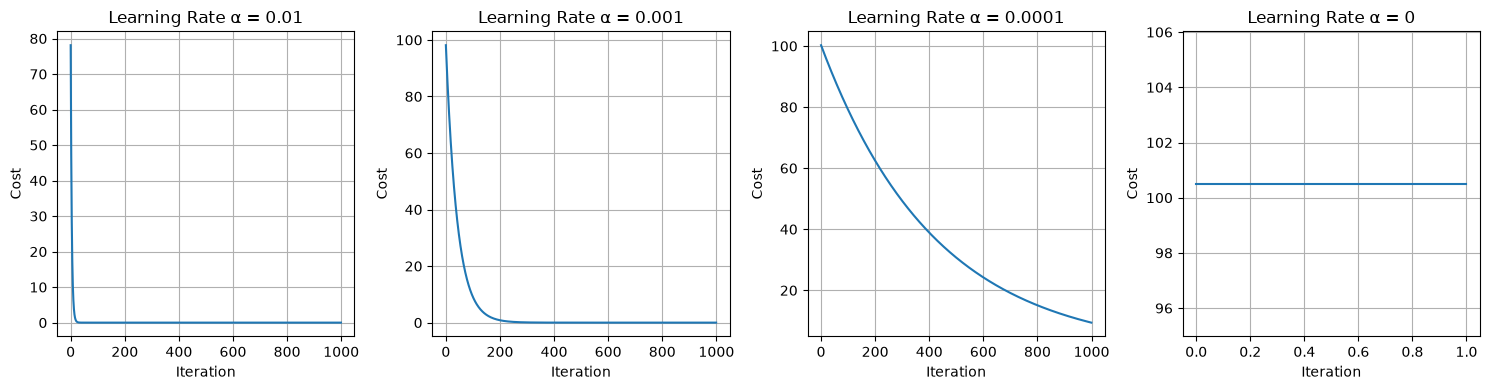

In [5]:
# Cost Function - Loss every iteration
import matplotlib.pyplot as plt

histories = [lr1.history, lr2.history, lr3.history, lr4.history]
alphas = [0.01, 0.001, 0.0001, 0]

fig, axes = plt.subplots(1, 4, figsize=(15, 4))

for i, (history, alpha) in enumerate(zip(histories, alphas)):
    axes[i].plot(history)
    axes[i].set_title(f"Learning Rate α = {alpha}")
    axes[i].set_xlabel("Iteration")
    axes[i].set_ylabel("Cost")
    axes[i].grid(True)

plt.tight_layout()
plt.show()